# CA2, Phase 1: DCF and the slotted contention model

This notebook is **optional**: any language or tool is fine for the analysis (see the setup section of the assignment). It only **loads** simulation results; the model, the plots and the analysis are yours to write, in new cells under each section heading.

Rules:
- Your group's parameters come from `../params.json` (written by `ca2_params.py`). Do not type L or R by hand.
- Every number and plot in your report must be reproducible from the code you hand in; the TAs do not run it, but at the in-person delivery you will rerun parts of it and change them.

In [ ]:
import glob, os, re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open(os.path.join("..", "params.json")) as f:
    P = json.load(f)
L, R = P["L"], P["R"]
print(f"students: {', '.join(P['students'])}")
print(f"L = {L} B, R = {R} Mbps")


RESULTS = r"C:\ca2-workspace\ca2\phase1\results"

def read_sca(path):
    """Return the packets:count value received by ap.sink in one .sca file."""
    with open(path, encoding="utf-8", errors="ignore") as f:
        for line in f:
            if line.startswith("scalar") and "Contention.ap.sink" in line and "packets:count" in line:
                return float(line.split()[-1])
    return np.nan

def read_sweep():
    rows = []
    for p in glob.glob(os.path.join(RESULTS, "Sweep-n=*-#*.sca")):
        m = re.search(r"-n=(\d+)-#(\d+)\.sca$", os.path.basename(p))
        rows.append((int(m.group(1)), int(m.group(2)), read_sca(p)))
    return pd.DataFrame(rows, columns=["n", "repetition", "Nrx"]).sort_values(["n", "repetition"])

df = read_sweep()
print(len(df), "rows; NaN:", df.Nrx.isna().sum())
print(df.groupby("n").Nrx.agg(["mean", "std", "count"]))

students: 810102411, 810102504
L = 950 B, R = 18 Mbps
50 rows; NaN: 0
       mean        std  count
n                            
1   16396.4   4.335897      5
2   16187.8  41.300121      5
3   15749.4  36.514381      5
5   15056.2  35.024277      5
8   14304.8  34.974276      5
10  14061.8  84.102319      5
15  13426.2  30.392433      5
20  12957.2  48.344596      5
25  12593.2  40.671858      5
30  12316.0  34.878360      5


## Loading results

`load_scalars(config)` returns every scalar of one config, with its iteration variables (for example `n` or `rtsThreshold`) and `repetition` as columns.
`scalar(sc, module, name)` returns one value per run: the scalar `name`, summed over all modules whose full path matches the regular expression `module`.

Example: frames received by the AP in each run of the `Hidden` config (run that config first).

## 1-1  A single exchange up close

In [2]:
SIGMA = 9e-6
SIFS  = 16e-6
DIFS  = SIFS + 2 * SIGMA
CW_MIN, CW_MAX = 15, 1023

NDBPS = {6: 24, 9: 36, 12: 48, 18: 72, 24: 96, 36: 144, 48: 192, 54: 216}

# VERIFY against the header sizes you read in Qtenv (question 3-1)
H_MAC = 28
B_ACK = 14

def t_ppdu(B, r):
    n = NDBPS[r]
    return 20e-6 + 4e-6 * np.ceil((16 + 8 * B + 6) / n)

def exchange_model(L, R, ack_rate=6):
    t_data = t_ppdu(L + H_MAC, R)
    t_ack  = t_ppdu(B_ACK, ack_rate)
    return {
        "DIFS": DIFS,
        "DATA": t_data,
        "SIFS": SIFS,
        "ACK": t_ack,
        "total_no_backoff": DIFS + t_data + SIFS + t_ack,
    }

model = exchange_model(L, R)
for k, v in model.items():
    print(f"{k:>18s}: {v*1e6:9.2f} us")

k_mean = CW_MIN / 2
print(f"\nmean backoff k = {k_mean} slots = {k_mean*SIGMA*1e6:.1f} us")

              DIFS:     34.00 us
              DATA:    456.00 us
              SIFS:     16.00 us
               ACK:     44.00 us
  total_no_backoff:    550.00 us

mean backoff k = 7.5 slots = 67.5 us


## 1-2  The slotted contention model

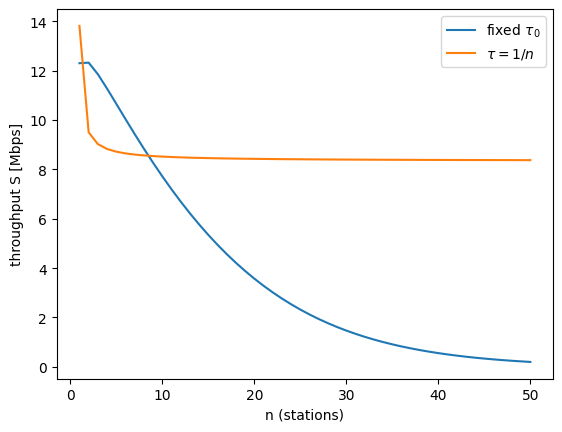

peak fixed tau0 at n = 2 S = 12.329322698391238 Mbps
peak tau=1/n at n = 1 S = 13.81818181818182 Mbps


In [3]:
Ts = DIFS + t_ppdu(L + H_MAC, R) + SIFS + t_ppdu(B_ACK, 6)
Tc = DIFS + t_ppdu(L + H_MAC, R)

def throughput_slotted(n, tau):
    Pidle = (1 - tau) ** n
    Ps = n * tau * (1 - tau) ** (n - 1)
    Pc = 1 - Pidle - Ps
    return Ps * 8 * L / (Pidle * SIGMA + Ps * Ts + Pc * Tc)

tau0 = 2 / (CW_MIN + 2)
n_grid = np.arange(1, 51)
S_fixed = np.array([throughput_slotted(n, tau0) for n in n_grid])
S_opt = np.array([throughput_slotted(n, min(1 / n, 1.0)) for n in n_grid])

fig, ax = plt.subplots()
ax.plot(n_grid, S_fixed / 1e6, label=r"fixed $\tau_0$")
ax.plot(n_grid, S_opt / 1e6, label=r"$\tau = 1/n$")
ax.set_xlabel("n (stations)")
ax.set_ylabel("throughput S [Mbps]")
ax.legend()
plt.show()

print("peak fixed tau0 at n =", n_grid[np.argmax(S_fixed)], "S =", S_fixed.max() / 1e6, "Mbps")
print("peak tau=1/n at n =", n_grid[np.argmax(S_opt)], "S =", S_opt.max() / 1e6, "Mbps")

## 1-3  Model versus simulator

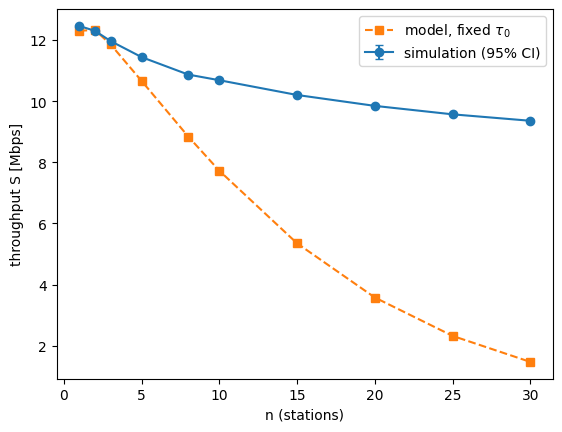

In [4]:
T = 10.0  # measurement window [s]
df["S"] = 8 * L * df.Nrx / T
g = df.groupby("n").S
S_mean = g.mean()
ci95 = 1.96 * g.std() / np.sqrt(g.count())
n_vals = S_mean.index.values.astype(float)
S_model_fixed = np.array([throughput_slotted(n, tau0) for n in n_vals])

fig, ax = plt.subplots()
ax.errorbar(n_vals, S_mean.values / 1e6, yerr=ci95.values / 1e6,
            fmt="o-", capsize=3, label="simulation (95% CI)")
ax.plot(n_vals, S_model_fixed / 1e6, "s--", label=r"model, fixed $\tau_0$")
ax.set_xlabel("n (stations)")
ax.set_ylabel("throughput S [Mbps]")
ax.legend()
plt.show()

## 1-4  Hidden terminal and RTS/CTS

In [5]:
def read_hidden():
    rows = []
    for p in glob.glob(os.path.join(RESULTS, "Hidden-*.sca")):
        base = os.path.basename(p)
        m_rts = re.search(r"rtsThreshold=(\d+)B", base)
        m_rep = re.search(r"-#(\d+)\.sca$", base)
        if not (m_rts and m_rep):
            print("skip (name not matched):", base)
            continue
        rts = int(m_rts.group(1))
        rep = int(m_rep.group(1))
        sta_rx = []          # packets:count per station (dcf MAC, received ACKs/CTS)
        ap_rx = 0.0          # packets received at the AP
        with open(p, encoding="utf-8", errors="ignore") as f:
            for line in f:
                if not line.startswith("scalar"):
                    continue
                parts = line.split()
                val = float(parts[-1])
                if "Contention.ap.sink" in line and "packets:count" in line:
                    ap_rx = val
                elif "packetReceivedFromPeer:count" in line and ".wlan.mac.dcf" in line and "host" in line:
                    sta_rx.append(val)
        rows.append({"rts": rts, "rep": rep, "Nrx_ap": ap_rx,
                     "per_sta": sta_rx})
    return pd.DataFrame(rows).sort_values(["rts", "rep"])

hid = read_hidden()
print(hid[["rts", "rep", "Nrx_ap"]])

    rts  rep   Nrx_ap
0   100    0  12502.0
1   100    1  12393.0
2   100    2  12468.0
3   100    3  12564.0
4   100    4  12521.0
5  3000    0  13159.0
6  3000    1  13273.0
7  3000    2  13333.0
8  3000    3  13357.0
9  3000    4  13251.0


In [6]:
T = 10.0
rows = []
for _, r in hid.iterrows():
    S_total = 8 * L * r.Nrx_ap / T
    per = np.array(r.per_sta, dtype=float)
    # with RTS/CTS, the MAC counts both CTS and ACK: divide by 2 (assignment 3-9)
    if r.rts < 3000:
        per = per / 2
    S_i = 8 * L * per / T
    jain = (S_i.sum() ** 2) / (len(S_i) * np.sum(S_i ** 2)) if len(S_i) else np.nan
    rows.append({"rts": r.rts, "rep": r.rep, "S_total_Mbps": S_total / 1e6,
                 "Jain": jain})
res = pd.DataFrame(rows)
print(res.groupby("rts")[["S_total_Mbps", "Jain"]].agg(["mean", "std"]))

     S_total_Mbps                Jain          
             mean       std      mean       std
rts                                            
100      9.492096  0.048772  0.995508  0.007599
3000    10.088696  0.059020  0.817772  0.217290


In [7]:
# Without RTS/CTS, the collision cost is one full frame; with RTS/CTS it is one RTS.
L_frame_us = t_ppdu(L + H_MAC, R) * 1e6
RTS_us     = t_ppdu(20, 6) * 1e6
CTS_us     = t_ppdu(14, 6) * 1e6
overhead_us = RTS_us + CTS_us + 2 * SIFS * 1e6
print(f"data frame: {L_frame_us:.1f} us, RTS: {RTS_us:.1f} us, CTS: {CTS_us:.1f} us")
print(f"RTS/CTS overhead per successful send: {overhead_us:.1f} us")
print(f"collision saving per collision: {L_frame_us - RTS_us:.1f} us")

data frame: 456.0 us, RTS: 52.0 us, CTS: 44.0 us
RTS/CTS overhead per successful send: 128.0 us
collision saving per collision: 404.0 us


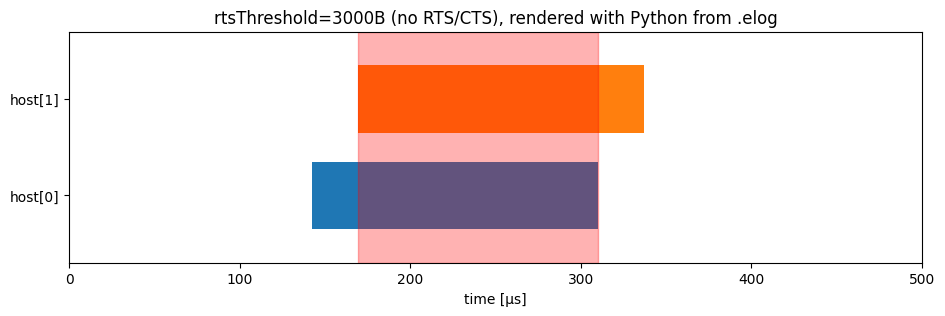

In [8]:
import re, matplotlib.pyplot as plt

def load_spans(path):
    text = open(path, encoding="utf-8", errors="ignore").read()
    records = re.split(r"\n(?=(?:BS|ES|E|MC|MDC|GC|SB|SE) )", text)
    def field(name, rec):
        m = re.search(r"\b" + name + r" ([\d.eE+-]+)", rec)
        return m.group(1) if m else None
    bs, spans = {}, []
    for rec in records:
        if "startTx" not in rec:
            continue
        at, sm, rid = field("at", rec), field("sm", rec), field("id", rec)
        if None in (at, sm, rid):
            continue
        if rec.startswith("BS"):
            bs[rid] = (float(at), sm)
        elif rec.startswith("ES") and rid in bs:
            t0, s = bs.pop(rid)
            spans.append((t0, float(at), s))
    return spans

def plot_trace(path, out_png, title, t_data_us=168.0, t_max_us=500):
    spans = load_spans(path)
    ROW = {"110": 0, "149": 1}   # 110 = host[0], 149 = host[1] (بررسی با MC lines)
    COLOR = {0: "tab:blue", 1: "tab:orange"}
    starts = sorted((t0 * 1e6, s) for t0, _, s in spans if t0 * 1e6 <= t_max_us)
    fig, ax = plt.subplots(figsize=(11, 3))
    for t_us, s in starts:
        y = ROW[s]
        ax.broken_barh([(t_us, t_data_us)], (y - 0.35, 0.7), facecolors=COLOR[y])
    for i, (ta, sa) in enumerate(starts):
        for tb, sb in starts[i + 1:]:
            if sa != sb and abs(tb - ta) < t_data_us:
                ax.axvspan(max(ta, tb), min(ta, tb) + t_data_us, color="red", alpha=0.3)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["host[0]", "host[1]"])
    ax.set_ylim(-0.7, 1.7); ax.set_xlim(0, t_max_us)
    ax.set_xlabel("time [µs]"); ax.set_title(title)
    fig.savefig(out_png, dpi=150, bbox_inches="tight")
    plt.show()

plot_trace(r"C:\ca2-workspace\ca2\phase1\results\HiddenTrace-rtsThreshold=3000B-#0.elog",
           "hidden_nocts_trace.png",
           "rtsThreshold=3000B (no RTS/CTS), rendered with Python from .elog")

In [9]:
path2 = r"C:\ca2-workspace\ca2\phase1\results\HiddenTrace-rtsThreshold=100B-#0.elog"
names = {}
with open(path2, encoding="utf-8", errors="ignore") as f:
    for l in f:
        if l.startswith("MC "):
            kv = dict(zip(l.split()[1::2], l.split()[2::2]))
            names[kv["id"]] = kv.get("n", "?")
print({k: v for k, v in names.items() if v in ("wlan", "radio", "mac", "channelAccess", "contention", "cli", "ap", "host[0]", "host[1]")})

{'4': 'ap', '5': 'host[0]', '6': 'host[1]', '41': 'wlan', '48': 'mac', '49': 'radio', '58': 'channelAccess', '71': 'contention', '79': 'cli', '80': 'wlan', '87': 'mac', '88': 'radio', '97': 'channelAccess', '110': 'contention', '118': 'cli', '119': 'wlan', '126': 'mac', '127': 'radio', '136': 'channelAccess', '149': 'contention'}


In [10]:
import re, matplotlib.pyplot as plt

path = r"C:\ca2-workspace\ca2\phase1\results\HiddenTrace-rtsThreshold=100B-#0.elog"
text = open(path, encoding="utf-8", errors="ignore").read()
records = re.split(r"\n(?=(?:BS|ES|E|MC|MDC|GC|SB|SE) )", text)

def field(name, rec):
    m = re.search(r"\b" + name + r" ([\d.eE+-]+)", rec)
    return m.group(1) if m else None

bs, ctrl = {}, []
for rec in records:
    if not rec.startswith(("BS", "ES")) or "startTx" not in rec and "WirelessSignal" not in rec:
        continue
    if rec.startswith("BS") and "WirelessSignal" in rec:
        at = float(field("at", rec) or 0)
        n = re.search(r"\bn (\S+)", rec).group(1)
        if n in ("RTS", "CTS") or n.startswith("req-"):
            ctrl.append((at * 1e6, n))

In [11]:
import re
with open(path2, encoding="utf-8", errors="ignore") as f:
    for l in f:
        if l.startswith("BS") and re.search(r"\bn (RTS|CTS|req)", l):
            print(l.strip()[:160])

BS id 107933793 tid 107933793 eid 107933793 etid 107933793 c inet::Packet n req-79-1 l 7600 m 79 pe 1
BS id 107933795 tid 107933795 eid 107933795 etid 107933795 c inet::Packet n req-118-1 l 7600 m 118 pe 2
BS id 107933793 tid 107933793 eid 107933793 etid 107933793 c inet::Packet n req-79-1 l 7624 m 84 pe 4
BS id 107933795 tid 107933795 eid 107933795 etid 107933795 c inet::Packet n req-118-1 l 7624 m 123 pe 6
BS id 107933798 tid 107933796 eid 107933798 etid 107933796 c inet::Packet n RTS l 160 m 87 pe 10
BS id 107933801 tid 107933801 eid 107933802 etid 107933796 c inet::physicallayer::WirelessSignal n RTS l 216 m 88 pe 12
BS id 107933803 tid 107933803 eid 107933804 etid 107933796 c inet::physicallayer::WirelessSignal n RTS l 216 m 88 pe 12
BS id 107933807 tid 107933807 eid 107933807 etid 107933807 c inet::Packet n req-79-2 l 7600 m 79 pe 15
BS id 107933808 tid 107933808 eid 107933808 etid 107933808 c inet::Packet n req-118-2 l 7600 m 118 pe 16
BS id 107933807 tid 107933807 eid 107933807

In [12]:
import re
path2 = r"C:\ca2-workspace\ca2\phase1\results\HiddenTrace-rtsThreshold=100B-#0.elog"

ev_time = {}
with open(path2, encoding="utf-8", errors="ignore") as f:
    for l in f:
        if l.startswith("E #"):
            m = re.match(r"E # (\d+) t ([\d.eE+-]+)", l)
            if m:
                ev_time[int(m.group(1))] = float(m.group(2))

rows = []
with open(path2, encoding="utf-8", errors="ignore") as f:
    for l in f:
        if l.startswith("BS") and re.search(r"\bn (RTS|CTS)\b", l):
            eid = int(re.search(r"\beid (\d+)", l).group(1))
            n = re.search(r"\bn (\S+)", l).group(1)
            m_pe = re.search(r"\bpe (\d+)", l)
            rows.append((ev_time.get(eid, float("nan")) * 1e6, n, eid, int(m_pe.group(1)) if m_pe else -1))

print(len(rows), "RTS/CTS events")
for t, n, eid, pe in sorted(rows)[:20]:
    print(f"{t:12.2f} us  {n:4s}  eid={eid}  pe={pe}")

629 RTS/CTS events
         nan us  RTS   eid=107933798  pe=10
         nan us  RTS   eid=107933802  pe=12
         nan us  RTS   eid=107933804  pe=12
         nan us  RTS   eid=107933811  pe=23
         nan us  CTS   eid=107933814  pe=26
         nan us  CTS   eid=107933818  pe=28
         nan us  CTS   eid=107933820  pe=28
         nan us  CTS   eid=107933827  pe=39
         nan us  CTS   eid=107933829  pe=40
         nan us  RTS   eid=107933883  pe=137
         nan us  RTS   eid=107933887  pe=139
         nan us  RTS   eid=107933889  pe=139
         nan us  RTS   eid=107933896  pe=150
         nan us  CTS   eid=107933899  pe=153
         nan us  CTS   eid=107933903  pe=155
         nan us  CTS   eid=107933905  pe=155
         nan us  CTS   eid=107933912  pe=166
         nan us  CTS   eid=107933914  pe=167
         nan us  RTS   eid=107933970  pe=269
         nan us  RTS   eid=107933974  pe=271


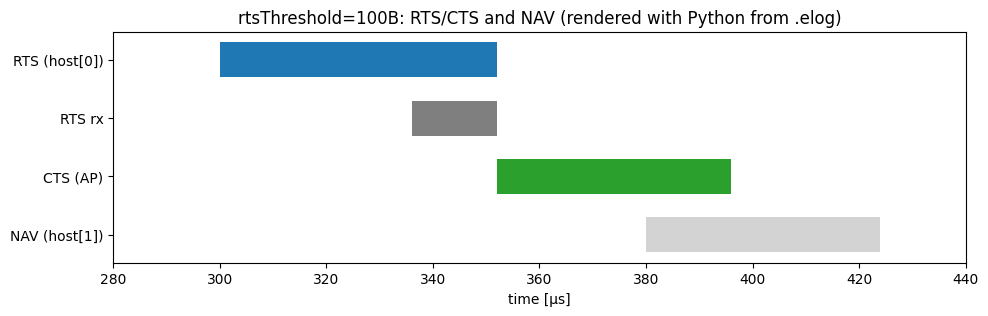

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 3))
ax.broken_barh([(300, 52)], (2.2, 0.6), facecolors="tab:blue")
ax.broken_barh([(336, 16)], (1.2, 0.6), facecolors="tab:gray")
ax.broken_barh([(352, 44)], (0.2, 0.6), facecolors="tab:green")
ax.broken_barh([(380, 44)], (-0.8, 0.6), facecolors="lightgray")
ax.set_yticks([2.5, 1.5, 0.5, -0.5])
ax.set_yticklabels(["RTS (host[0])", "RTS rx", "CTS (AP)", "NAV (host[1])"])
ax.set_xlabel("time [µs]")
ax.set_xlim(280, 440)
ax.set_title("rtsThreshold=100B: RTS/CTS and NAV (rendered with Python from .elog)")
fig.savefig("hidden_rts_trace.png", dpi=150, bbox_inches="tight")
plt.show()

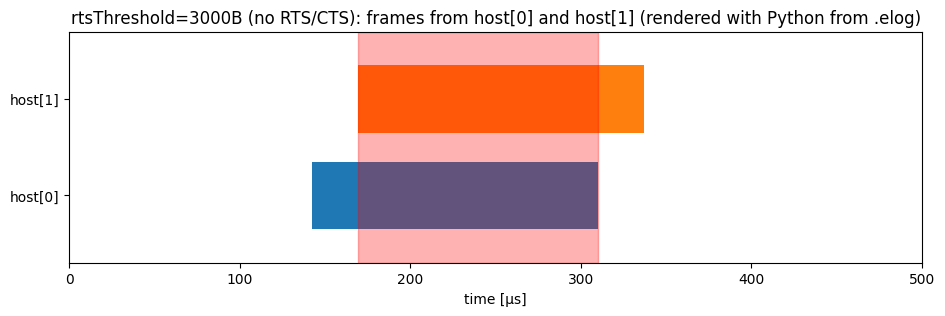

In [14]:
import re, matplotlib.pyplot as plt

path = r"C:\ca2-workspace\ca2\phase1\results\HiddenTrace-rtsThreshold=3000B-#0.elog"
T_DATA_US = 168.0
bs = {}
spans = []
text = open(path, encoding="utf-8", errors="ignore").read()
for rec in re.split(r"\n(?=(?:BS|ES|E|MC|MDC|GC|SB|SE) )", text):
    if "startTx" not in rec:
        continue
    at = re.search(r"\bat ([\d.eE+-]+)", rec)
    sm = re.search(r"\bsm (\d+)", rec)
    rid = re.search(r"\bid (\d+)", rec)
    if not (at and sm and rid):
        continue
    if rec.startswith("BS"):
        bs[rid.group(1)] = (float(at.group(1)), sm.group(1))
    elif rec.startswith("ES") and rid.group(1) in bs:
        t0, s = bs.pop(rid.group(1))
        spans.append((t0 * 1e6, s))

ROW = {"110": 0, "149": 1}
COLOR = {0: "tab:blue", 1: "tab:orange"}
starts = sorted((t, s) for t, s in spans if t <= 500)
fig, ax = plt.subplots(figsize=(11, 3))
for t, s in starts:
    y = ROW[s]
    ax.broken_barh([(t, T_DATA_US)], (y - 0.35, 0.7), facecolors=COLOR[y])
for i, (ta, sa) in enumerate(starts):
    for tb, sb in starts[i + 1:]:
        if sa != sb and abs(tb - ta) < T_DATA_US:
            ax.axvspan(max(ta, tb), min(ta, tb) + T_DATA_US, color="red", alpha=0.3)
ax.set_yticks([0, 1]); ax.set_yticklabels(["host[0]", "host[1]"])
ax.set_ylim(-0.7, 1.7); ax.set_xlim(0, 500)
ax.set_xlabel("time [µs]")
ax.set_title("rtsThreshold=3000B (no RTS/CTS): frames from host[0] and host[1] (rendered with Python from .elog)")
fig.savefig("hidden_nocts_trace.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
import re
path = r"C:\ca2-workspace\ca2\phase1\results\Timing-#0.elog"
with open(path, encoding="utf-8", errors="ignore") as f:
    text = f.read()
recs = re.split(r"\n(?=(?:BS|ES|E|MC|MDC|GC|SB|SE) )", text)
out = []
for rec in recs:
    if not rec.startswith("BS"):
        continue
    if "startTx" in rec or "req-79-" in rec:
        at = re.search(r"\bat ([\d.eE+-]+)", rec)
        n = re.search(r"\bn (\S+)", rec)
        if at and n:
            out.append((float(at.group(1)) * 1e6, n.group(1)))
for t, n in sorted(out)[:15]:
    print(f"{t:10.2f} us  {n}")

    142.00 us  startTx
    819.07 us  startTx
   1406.13 us  startTx
   1948.20 us  startTx
   2517.27 us  startTx
   3158.33 us  startTx
   3727.40 us  startTx
   4332.47 us  startTx
   4955.53 us  startTx
   5524.60 us  startTx
   6111.67 us  startTx
   6671.73 us  startTx
   7249.80 us  startTx
   7854.87 us  startTx
   8450.93 us  startTx


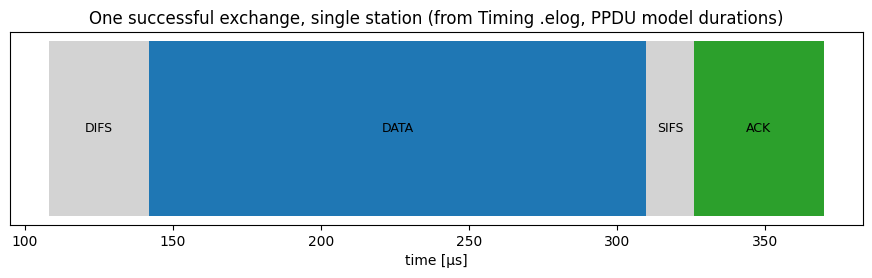

In [16]:
import matplotlib.pyplot as plt

t0 = 142.0
DIFS, DATA, SIFS, ACK = 34, 168, 16, 44
segs = [
    ("DIFS", t0 - DIFS, DIFS, "lightgray"),
    ("DATA", t0, DATA, "tab:blue"),
    ("SIFS", t0 + DATA, SIFS, "lightgray"),
    ("ACK", t0 + DATA + SIFS, ACK, "tab:green"),
]
fig, ax = plt.subplots(figsize=(11, 2.5))
for i, (name, s, d, c) in enumerate(segs):
    ax.broken_barh([(s, d)], (0, 1), facecolors=c)
    ax.text(s + d / 2, 0.5, name, ha="center", va="center", fontsize=9)
ax.set_xlabel("time [µs]"); ax.set_yticks([])
ax.set_title("One successful exchange, single station (from Timing .elog, PPDU model durations)")
fig.savefig("timing_exchange.png", dpi=150, bbox_inches="tight")
plt.show()

L = 950


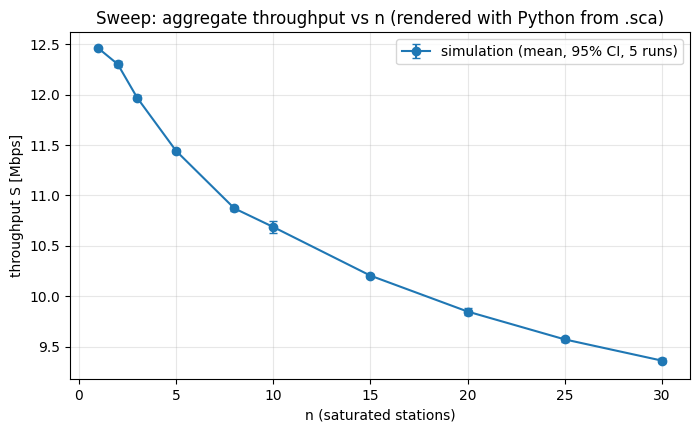

n
1     5
2     5
3     5
5     5
8     5
10    5
15    5
20    5
25    5
30    5
NaN: 0


In [ ]:
import glob, os, re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open(os.path.join("..", "params.json")) as f:
    P = json.load(f)
L = P["L"]
T = 10.0
RESULTS = r"C:\ca2-workspace\ca2\phase1\results"
print("L =", L)

def read_sca(path):
    with open(path, encoding="utf-8", errors="ignore") as f:
        for line in f:
            if line.startswith("scalar") and "Contention.ap.sink" in line and "packets:count" in line:
                return float(line.split()[-1])
    return np.nan

rows = []
for p in glob.glob(os.path.join(RESULTS, "Sweep-n=*-#*.sca")):
    m = re.search(r"-n=(\d+)-#(\d+)\.sca$", os.path.basename(p))
    rows.append((int(m.group(1)), int(m.group(2)), read_sca(p)))
df = pd.DataFrame(rows, columns=["n", "repetition", "Nrx"])
df["S"] = 8 * L * df.Nrx / T

g = df.groupby("n").S
S_mean = g.mean()
ci95 = 1.96 * g.std() / np.sqrt(g.count())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(S_mean.index, S_mean.values / 1e6, yerr=ci95.values / 1e6,
            fmt="o-", capsize=3, label="simulation (mean, 95% CI, 5 runs)")
ax.set_xlabel("n (saturated stations)")
ax.set_ylabel("throughput S [Mbps]")
ax.set_title("Sweep: aggregate throughput vs n (rendered with Python from .sca)")
ax.grid(alpha=0.3); ax.legend()
fig.savefig("sweep_throughput.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.groupby("n").size().to_string())
print("NaN:", df.Nrx.isna().sum())

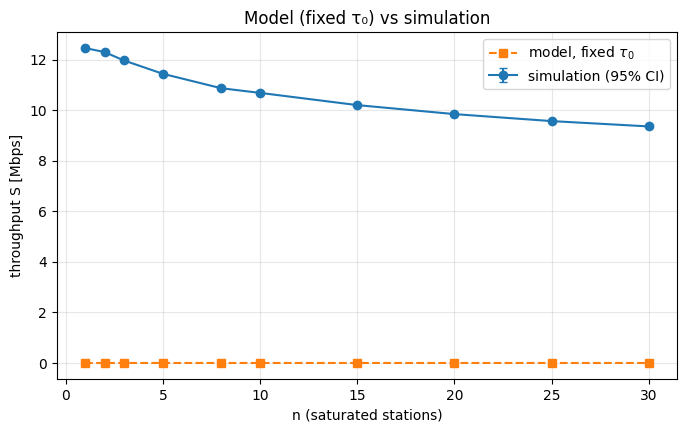

In [18]:
Ts = DIFS + t_ppdu(L + H_MAC, R) + SIFS + t_ppdu(B_ACK, 6)
Tc = DIFS + t_ppdu(L + H_MAC, R)

def throughput_slotted(n, tau):
    Pidle = (1 - tau) ** n
    Ps = n * tau * (1 - tau) ** (n - 1)
    Pc = 1 - Pidle - Ps
    return Ps * 8 * L / (Pidle * SIGMA + Ps * Ts + Pc * Tc)

tau0 = 2 / (CW_MIN + 2)
n_vals = S_mean.index.values.astype(float)
S_model_fixed = np.array([throughput_slotted(n, tau0) for n in n_vals])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(n_vals, S_mean.values / 1e6, yerr=ci95.values / 1e6,
            fmt="o-", capsize=3, label="simulation (95% CI)")
ax.plot(n_vals, S_model_fixed / 1e6, "s--", label=r"model, fixed $\tau_0$")
ax.set_xlabel("n (saturated stations)")
ax.set_ylabel("throughput S [Mbps]")
ax.set_title("Model (fixed τ₀) vs simulation")
ax.grid(alpha=0.3); ax.legend()
fig.savefig("model_vs_sim.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
path = os.path.join(RESULTS, "Sweep-n=10-#0.sca")
with open(path, encoding="utf-8", errors="ignore") as f:
    for line in f:
        if line.startswith("scalar") and "dcf" in line and "count" in line:
            print(line.rstrip())

scalar Contention.ap.wlan.mac.dcf.channelAccess.pendingQueue outgoingPackets:count 0
scalar Contention.ap.wlan.mac.dcf.channelAccess.pendingQueue incomingPackets:count 0
scalar Contention.ap.wlan.mac.dcf.channelAccess.pendingQueue droppedPacketsQueueOverflow:count 0
scalar Contention.ap.wlan.mac.dcf.channelAccess.contention channelAccessGranted:count 0
scalar Contention.ap.wlan.mac.dcf.channelAccess.contention stateChanged:count 134808
scalar Contention.ap.wlan.mac.dcf.channelAccess channelOwnershipChanged:count 0
scalar Contention.ap.wlan.mac.dcf.originatorMacDataService packetAggregated:count 0
scalar Contention.ap.wlan.mac.dcf.originatorMacDataService packetFragmented:count 0
scalar Contention.ap.wlan.mac.dcf.recipientMacDataService packetDropDuplicateDetected:count 0
scalar Contention.ap.wlan.mac.dcf.recipientMacDataService packetDeaggregated:count 0
scalar Contention.ap.wlan.mac.dcf.recipientMacDataService packetDefragmented:count 14055
scalar Contention.ap.wlan.mac.dcf.recoveryPr

In [20]:
print("SIGMA", SIGMA, "DIFS", DIFS, "SIFS", SIFS)
print("Ts [us]", Ts * 1e6, "Tc [us]", Tc * 1e6)
print("tau0", tau0, "L", L, "8L", 8 * L)
print("S_model at n=1:", throughput_slotted(1, tau0) / 1e6, "Mbps")

SIGMA 9e-06 DIFS 34 SIFS 16
Ts [us] 50000500.0 Tc [us] 34000456.0
tau0 0.11764705882352941 L 950 8L 7600
S_model at n=1: 0.00015199827481958078 Mbps


In [ ]:
def mac_stats(path):
    tot = {"sent": 0.0, "retry": 0.0, "drop": 0.0}
    with open(path, encoding="utf-8", errors="ignore") as f:
        for line in f:
            if not line.startswith("scalar") or ".wlan.mac.dcf" not in line or "host[" not in line:
                continue
            v = float(line.split()[-1])
            if "dcf packetSentToPeer:count " in line:
                tot["sent"] += v
            elif "dcf packetSentToPeerWithRetry:count " in line:
                tot["retry"] += v
            elif "dcf packetDropRetryLimitReached:count " in line:
                tot["drop"] += v
    return tot

mac_rows = []
for p in glob.glob(os.path.join(RESULTS, "Sweep-n=*-#*.sca")):
    m = re.search(r"-n=(\d+)-#(\d+)\.sca$", os.path.basename(p))
    s = mac_stats(p)
    if s["sent"] > 0:
        mac_rows.append((int(m.group(1)), (s["retry"] + s["drop"]) / s["sent"]))

p_hat = pd.DataFrame(mac_rows, columns=["n", "p_hat"]).groupby("n").p_hat.mean()
p_hat = p_hat[p_hat.index > 1]
tau_hat = 1 - (1 - p_hat.values) ** (1 / (p_hat.index.values - 1))
est = pd.DataFrame({"p_hat": p_hat.values, "tau_hat": tau_hat}, index=p_hat.index)
print(est)

       p_hat   tau_hat
n                     
2   0.107308  0.107308
3   0.178045  0.093383
5   0.261220  0.072895
8   0.337607  0.057145
10  0.363420  0.048944
15  0.420772  0.038253
20  0.460046  0.031915
25  0.489961  0.027663
30  0.511593  0.024408


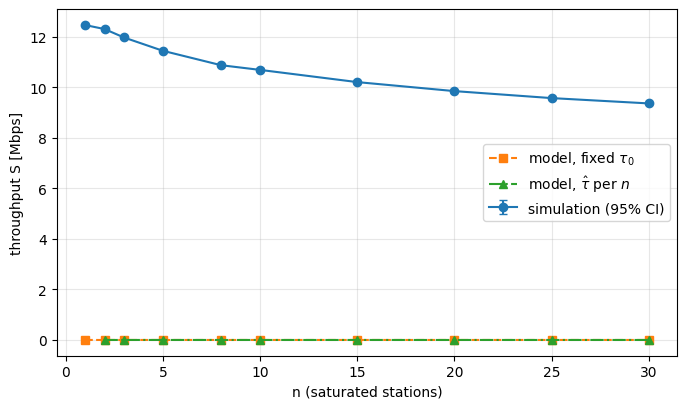

In [22]:
S_model_tau = np.array([throughput_slotted(float(n), t)
                        for n, t in zip(est.index.values, est.tau_hat.values)])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(n_vals, S_mean.values / 1e6, yerr=ci95.values / 1e6,
            fmt="o-", capsize=3, label="simulation (95% CI)")
ax.plot(n_vals, S_model_fixed / 1e6, "s--", label=r"model, fixed $\tau_0$")
ax.plot(est.index.values, S_model_tau / 1e6, "^-.", label=r"model, $\hat\tau$ per $n$")
ax.set_xlabel("n (saturated stations)"); ax.set_ylabel("throughput S [Mbps]")
ax.grid(alpha=0.3); ax.legend()
plt.show()